# Section 1: Data Tidying & Reshaping (WHO Tuberculosis Dataset)

**Name:** Ricardo Mohammed  
**Student ID:** 7500382

## Project Overview
This notebook demonstrates the process of tidying and reshaping a "wide" dataset into a "long" (tidy) format, adhering to the core principles of tidy data. As part of the group assignment for Lab 2, this module focuses specifically on the **Tidying & Reshaping** use case. 

## Dataset
The dataset used is the **WHO Tuberculosis (TB) Notifications** data. In its raw form, the data is structured in a "wide" format where different demographic and year combinations are spread across multiple column headers. This notebook transforms the data so that each variable forms a column and each observation forms a row.

## Key Objectives
1. **Data Acquisition:** Download and load the raw WHO TB dataset using relative paths.
2. **Data Tidying:** Use `pd.melt()` to reshape the data from wide to long format and clean the resulting variables.
3. **Database Integration:** Connect to a remote Neon PostgreSQL database and upload the tidied dataframe for group-wide access.
4. **Modular Architecture:** Utilize a modular Python structure (`src/` directory) to separate database connection logic and data processing functions from the main notebook execution.

## Tech Stack
- **Python** & **Pandas** for data manipulation and analysis.
- **SQLAlchemy** & **psycopg2** for relational database connectivity.
- **python-dotenv** for secure environment variable management.
- **Neon** (PostgreSQL) for cloud database hosting.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
from pathlib import Path

# 1. Setup paths to allow importing from the 'src' folder
# Since your notebook is in /notebooks, this adds the root project folder to the path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# 2. Import the modular database connection class
from src.neon_connect import DatabaseManager 

# 3. Initialize the connection 
# (The __init__ method in your class automatically loads the .env and connects)
db = DatabaseManager()

# 4. Setup data directory
Path("../data").mkdir(exist_ok=True)

print("🚀 Modules imported and database connected successfully.")

✅ Successfully connected to Neon PostgreSQL database.
🚀 Modules imported and database connected successfully.


### 2. Data Acquisition and Initial Inspection

**Dataset:** WHO Tuberculosis (TB) Notifications Data

**Source:** [WHO TB Dataset](https://raw.githubusercontent.com/tidyverse/tidyr/master/data-raw/who.csv)

**Initial Observations:**
- **Shape:** 7,240 rows × 60 columns
- **Structure:** Wide format with country/year identifiers and multiple diagnostic columns
- **Issue:** The dataset violates tidy data principles - diagnostic codes (e.g., `new_sp_m014`, `new_sp_f1524`) are stored as column headers instead of values

**Column Breakdown:**
- **Identifier variables:** `country`, `iso2`, `iso3`, `year`
- **Measured variables:** 56 diagnostic code columns representing TB cases by:
  - Diagnosis type (new_sp, new_sn, new_ep, newrel)
  - Gender (m=male, f=female, u=unknown)
  - Age group (014, 1524, 2534, 3544, 4554, 5564, 65)

**Next Step:** Reshape from wide to long format using `pd.melt()`

In [2]:
# 1. Download/Load the WHO Tuberculosis dataset
url = "https://raw.githubusercontent.com/tidyverse/tidyr/master/data-raw/who.csv"
file_path = "../data/who_tb.csv"

if not Path(file_path).exists():
    print("📥 Downloading WHO TB dataset...")
    df_raw = pd.read_csv(url)
    df_raw.to_csv(file_path, index=False)
else:
    df_raw = pd.read_csv(file_path)

print(f"✅ Loaded raw dataset. Shape: {df_raw.shape}")
print("\n--- First 5 Columns (Notice the 'wide' format) ---")
display(df_raw.head(3))
print("\n--- Column Names (These are the variables we need to melt!) ---")
print(df_raw.columns[:10].tolist(), "...")


✅ Loaded raw dataset. Shape: (7240, 60)

--- First 5 Columns (Notice the 'wide' format) ---


,country,iso2,iso3,year,new_sp_m014,new_sp_m1524,new_sp_m2534,new_sp_m3544,new_sp_m4554,new_sp_m5564,...,newrel_m4554,newrel_m5564,newrel_m65,newrel_f014,newrel_f1524,newrel_f2534,newrel_f3544,newrel_f4554,newrel_f5564,newrel_f65
0,Afghanistan,AF,AFG,1980,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,AF,AFG,1981,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AF,AFG,1982,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Column Names (These are the variables we need to melt!) ---
['country', 'iso2', 'iso3', 'year', 'new_sp_m014', 'new_sp_m1524', 'new_sp_m2534', 'new_sp_m3544', 'new_sp_m4554', 'new_sp_m5564'] ...


### 3. Tidying Process: Wide to Long Transformation

**Method:** `pd.melt()` with the following parameters:
- `id_vars`: ['country', 'iso2', 'iso3', 'year'] - columns to keep as identifiers
- `var_name`: 'diagnostic_code' - new column name for the melted column headers
- `value_name`: 'cases' - new column name for the values

**Results:**
- **Before:** 7,240 rows × 60 columns (wide format)
- **After:** 76,046 rows × 6 columns (long/tidy format)
- **Transformation:** Each row now represents a single observation (country + year + diagnostic code + case count)

**Data Quality Improvement:**
- Removed rows with `NaN` case counts (missing data)
- Converted `cases` column to integer type for cleaner analysis
- Reset index for clean sequential numbering

**Tidy Data Principles Satisfied:**
1. ✅ Each variable forms a column (country, year, diagnostic_code, cases)
2. ✅ Each observation forms a row
3. ✅ Each type of observational unit forms a table

In [3]:
# 1. Define the identifier variables (the columns that stay fixed)
id_vars = ['country', 'iso2', 'iso3', 'year']

# 2. Melt the dataframe from Wide to Long
df_tidy = pd.melt(
    df_raw, 
    id_vars=id_vars, 
    var_name='diagnostic_code', # The new column for the old headers
    value_name='cases'          # The new column for the values
)

# 3. Clean up: Drop rows where cases are NaN (missing data)
df_tidy = df_tidy.dropna(subset=['cases']).reset_index(drop=True)

# Convert cases to integer for cleaner look
df_tidy['cases'] = df_tidy['cases'].astype(int)

print(f"✅ Tidying complete!")
print(f"Reshaped from {df_raw.shape} (Wide) to {df_tidy.shape} (Long/Tidy)")
display(df_tidy.head(10))

✅ Tidying complete!
Reshaped from (7240, 60) (Wide) to (76046, 6) (Long/Tidy)


,country,iso2,iso3,year,diagnostic_code,cases
0,Afghanistan,AF,AFG,1997,new_sp_m014,0
1,Afghanistan,AF,AFG,1998,new_sp_m014,30
2,Afghanistan,AF,AFG,1999,new_sp_m014,8
3,Afghanistan,AF,AFG,2000,new_sp_m014,52
4,Afghanistan,AF,AFG,2001,new_sp_m014,129
5,Afghanistan,AF,AFG,2002,new_sp_m014,90
6,Afghanistan,AF,AFG,2003,new_sp_m014,127
7,Afghanistan,AF,AFG,2004,new_sp_m014,139
8,Afghanistan,AF,AFG,2005,new_sp_m014,151
9,Afghanistan,AF,AFG,2006,new_sp_m014,193


### 4. Advanced String Manipulation: Decoding Diagnostic Codes

**Problem:** The `diagnostic_code` column contains encoded information that needs to be extracted into separate variables for analysis.

**Encoding Scheme:** `new_sp_m014` breaks down as:
- `new_sp` = Diagnosis type (new smear-positive pulmonary TB)
- `m` = Gender (male)
- `014` = Age group (0-14 years)

**String Operations Used:**
1. **Regex Extraction:** `str.extract(r'^(new_\w+)_(m|f|u)(\d{3})$')`
   - Captures three groups: diagnosis type, gender code, age group
2. **Value Mapping:** `gender_map = {'m': 'Male', 'f': 'Female', 'u': 'Unknown'}`
   - Converts single-letter codes to readable labels

**Result:** Added three new columns:
- `diagnosis`: Type of TB diagnosis (e.g., "new_sp", "new_sn")
- `gender`: Patient gender (Male/Female/Unknown)
- `age_group`: Age range (e.g., "014", "1524")

**Benefit:** Enables granular analysis by diagnosis type, gender, and age group without parsing complex column names.

In [4]:
# The 'diagnostic_code' column contains encoded information: e.g., 'new_sp_m014'
# 'new_sp' = diagnosis type, 'm' = male, '014' = age 0-14.
# Let's extract these into separate columns using Regex.

# Extract the components
df_tidy[['diagnosis', 'gender', 'age_group']] = df_tidy['diagnostic_code'].str.extract(r'^(new_\w+)_(m|f|u)(\d{3})$')

# Map the codes to readable strings
gender_map = {'m': 'Male', 'f': 'Female', 'u': 'Unknown'}
df_tidy['gender'] = df_tidy['gender'].map(gender_map)

print("✅ Advanced string extraction complete.")
display(df_tidy[['country', 'year', 'diagnosis', 'gender', 'age_group', 'cases']].head(10))

✅ Advanced string extraction complete.


,country,year,diagnosis,gender,age_group,cases
0,Afghanistan,1997,new_sp,Male,014,0
1,Afghanistan,1998,new_sp,Male,014,30
2,Afghanistan,1999,new_sp,Male,014,8
3,Afghanistan,2000,new_sp,Male,014,52
4,Afghanistan,2001,new_sp,Male,014,129
5,Afghanistan,2002,new_sp,Male,014,90
6,Afghanistan,2003,new_sp,Male,014,127
7,Afghanistan,2004,new_sp,Male,014,139
8,Afghanistan,2005,new_sp,Male,014,151
9,Afghanistan,2006,new_sp,Male,014,193


### 5. Database Upload and Verification

**Process:**
1. Uploaded the tidied DataFrame to Neon PostgreSQL using `db.upload_dataframe()`
2. Used `if_exists='replace'` to ensure clean re-runs without duplicate data
3. Verified the upload by querying the database and displaying the first 5 rows

**Table Details:**
- **Table name:** `tidying_who_tb`
- **Rows uploaded:** 76,046
- **Columns:** 10 (country, iso2, iso3, year, diagnostic_code, cases, diagnosis, gender, age_group)

**Verification:** Successfully retrieved data from the database, confirming:
- ✅ Data integrity maintained during upload
- ✅ All columns present and correctly typed
- ✅ Database connection working properly

**Next Steps:** This tidied dataset is now ready for:
- Exploratory data analysis (EDA)
- Visualization of TB trends by country/year/demographics
- Integration with other team members' cleaned datasets

In [5]:
# Upload the tidy dataframe to the Neon database using the modular class
table_name = 'tidying_who_tb'

# Use the db object we created in Cell 1
db.upload_dataframe(df_tidy, table_name=table_name, if_exists='replace')

# Verify it's in the database by fetching it back
df_from_db = db.fetch_dataframe(f"SELECT * FROM {table_name} LIMIT 5")
print("\n--- Verified data from Neon Database ---")
display(df_from_db)

✅ Successfully uploaded 76046 rows to 'tidying_who_tb'.

--- Verified data from Neon Database ---


,country,iso2,iso3,year,diagnostic_code,cases,diagnosis,gender,age_group
0,Afghanistan,AF,AFG,1997,new_sp_m014,0,new_sp,Male,014
1,Afghanistan,AF,AFG,1998,new_sp_m014,30,new_sp,Male,014
2,Afghanistan,AF,AFG,1999,new_sp_m014,8,new_sp,Male,014
3,Afghanistan,AF,AFG,2000,new_sp_m014,52,new_sp,Male,014
4,Afghanistan,AF,AFG,2001,new_sp_m014,129,new_sp,Male,014


### Section 1 Summary

This notebook successfully:
1. Connected to a Neon PostgreSQL database
2. Loaded the WHO TB dataset (7,240 rows, wide format)
3. Tidied the data using `pd.melt()` (76,046 rows, long format)
4. Extracted encoded information using regex string operations
5. Uploaded the clean data to the database for group access

The tidied dataset is now ready for EDA and can be joined with other team members' cleaned datasets.

# Section 2: Automobile Data Cleaning, String Manipulation, and Neon PostgreSQL

This project applies the Cars section's cleaning concepts and the Billboard
section's string methods to a different automobile dataset. It inspects missing
data and duplicates, converts text measurements, documents imputation decisions,
visualizes results, exports reproducible outputs, and stores the results in Neon.

Dataset: [CarDekho Vehicle Dataset, Nehal Birla](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho),
file **Car details v3.csv**, supplied locally. The raw file contains 8,128 rows
and 13 columns. Advertised selling prices are in Indian rupees (INR).
This is a historical used-car dataset, not a current market valuation.


## 1. Setup and reproducibility
Use Python 3.10 or later. In a terminal, create a virtual environment and run
`python -m pip install -r requirements.txt`. Select that environment as the
notebook kernel. Keep the notebook beside `data/` and `src/`.

The local cleaning sections work without database credentials. To enable Neon,
copy `.env.example` to `.env` and paste your own PostgreSQL connection URL.
Never put the URL directly into a notebook cell. The database section uploads
automatically when a valid URL is configured.


In [6]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import datetime

RAW_PATH = Path("../data/raw/car_details_v3.csv")
PROJECT_ROOT = Path("..").resolve()

if not RAW_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {RAW_PATH.resolve()}")

PROCESSED = PROJECT_ROOT / "data" / "processed"

PROCESSED.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Dataset found:", RAW_PATH.resolve())

Dataset found: C:\Personal\Projects\cleaning-imputation-outliers\data\raw\car_details_v3.csv


## 2. Load and inspect the original data
`cars_raw` preserves the values loaded from the CSV. `source_row` is a lineage
field: it records the original data-row position (CSV line minus one). It is not
a vehicle identifier. The original bytes remain unchanged in `data/raw/`.


In [7]:
import pandas as pd

cars_raw = pd.read_csv(RAW_PATH)
required_columns = ["name", "year", "selling_price", "km_driven", "fuel", "seller_type",
                    "transmission", "owner", "mileage", "engine", "max_power", "torque", "seats"]
if list(cars_raw.columns) != required_columns:
    raise ValueError("Unexpected source columns; review this version before cleaning.")
print("Rows and columns:", cars_raw.shape)
display(cars_raw.head())
cars_raw.info()
display(cars_raw.describe(include="all").T)


Rows and columns: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,8128,2058,Maruti Swift Dzire VDI,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,8128.0,NaN,NaN,NaN,2013.804011,4.044249,1983.0,2011.0,2015.0,2017.0,2020.0
selling_price,8128.0,NaN,NaN,NaN,638271.807702,806253.403508,29999.0,254999.0,450000.0,675000.0,10000000.0
km_driven,8128.0,NaN,NaN,NaN,69819.510827,56550.554958,1.0,35000.0,60000.0,98000.0,2360457.0
fuel,8128,4,Diesel,4402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,8128,3,Individual,6766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,8128,2,Manual,7078,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,8128,5,First Owner,5289,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mileage,7907,393,18.9 kmpl,225,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engine,7907,121,1248 CC,1017,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data dictionary

| Column | Meaning | Treatment |
|---|---|---|
| name | Manufacturer, model, and variant | Keep raw; normalize whitespace; derive brand/model |
| year | Listed vehicle year | Validate; retain |
| selling_price | Listed selling price, INR | Validate positive; retain |
| km_driven | Total distance travelled, kilometres | Validate nonnegative; retain |
| fuel | Petrol, Diesel, CNG, or LPG | Standardize text case |
| seller_type | Seller category | Standardize text case and spacing |
| transmission | Manual or Automatic | Standardize text case and spacing |
| owner | Ownership category | Standardize text case and spacing |
| mileage | Fuel economy, not odometer distance | Extract value and unit separately |
| engine | Engine displacement with CC suffix | Derive numeric engine_cc |
| max_power | Engine power with bhp suffix | Derive numeric max_power_bhp |
| torque | Torque and RPM in inconsistent formats | Preserve; normalize spacing for inspection |
| seats | Seating capacity | Fill missing values using a categorical strategy |

Torque parsing is not forced into a single numeric value: the strings mix
units and RPM ranges. The raw field and `torque_text` remain available; missing
torque values are reported rather than invented.


## 3. Assess missing values and duplicates
`isna()` counts missing entries; `notna()` confirms valid values. Counts below
describe the original data before any rows are excluded.


In [8]:
missing_before = pd.DataFrame({
    "missing_count": cars_raw.isna().sum(),
    "missing_percent": (cars_raw.isna().mean() * 100).round(2),
    "non_missing_count": cars_raw.notna().sum(),
})
display(missing_before)
print("Repeated rows after the first occurrence:", cars_raw.duplicated().sum())
display(cars_raw.loc[cars_raw.duplicated(keep=False)].head(6))


,missing_count,missing_percent,non_missing_count
name,0,0.00,8128
year,0,0.00,8128
selling_price,0,0.00,8128
km_driven,0,0.00,8128
fuel,0,0.00,8128
seller_type,0,0.00,8128
transmission,0,0.00,8128
owner,0,0.00,8128
mileage,221,2.72,7907
engine,221,2.72,7907


Repeated rows after the first occurrence: 1202


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
31,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
32,Maruti Omni 8 Seater BSIV,2012,150000,35000,Petrol,Individual,Manual,Second Owner,14.0 kmpl,796 CC,35 bhp,6.1kgm@ 3000rpm,5.0
33,Hyundai i20 1.2 Asta Dual Tone,2018,730000,2388,Petrol,Individual,Manual,First Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
34,Maruti Vitara Brezza LDi,2017,650000,16200,Diesel,Individual,Manual,First Owner,24.3 kmpl,1248 CC,88.5 bhp,200Nm@ 1750rpm,5.0
35,Maruti Alto 800 CNG LXI Optional,2019,330000,10000,CNG,Individual,Manual,Second Owner,33.44 km/kg,796 CC,40.3 bhp,60Nm@ 3500rpm,4.0
36,Maruti Alto K10 VXI Airbag,2019,366000,15000,Petrol,Individual,Manual,First Owner,23.95 kmpl,998 CC,67.1 bhp,90Nm@ 3500rpm,5.0


## 4. Create a working copy and treat repeated rows
For this exercise, exact repeated records are treated as duplicate listings and
one copy is retained. Matching attributes cannot prove two rows refer to the
same physical vehicle because there is no listing ID or VIN. This assumption
may remove distinct cars with identical recorded attributes, so the original
CSV, raw database table, and excluded rows are retained for review.

The duplicate comparison uses the original 13 columns, excluding `source_row`.


In [9]:
# Remove Duplicate Records and Create the Working Copy

duplicate_mask = cars_raw.duplicated(keep="first")

# Retained in memory for the existing validation checks.
duplicate_rows = cars_raw.loc[duplicate_mask].copy()

cars_clean = cars_raw.loc[~duplicate_mask].copy()

# Preserve each retained record's original row position.
cars_clean.insert(0, "source_row", cars_clean.index + 1)

print("Original records:", len(cars_raw))
print("Duplicates removed:", len(duplicate_rows))
print("Retained records:", len(cars_clean))

Original records: 8128
Duplicates removed: 1202
Retained records: 6926


## 5. Clean text and extract manufacturer/model
String operations include `.str.strip()`, `.str.replace()`, `.str.lower()`,
`.str.upper()`, `.str.title()`, `.str.extract()`, and `.str.contains()`.
Normalizing already-consistent text may leave it unchanged; no artificial
errors are added. Original source columns remain available for comparison.

A first-word split alone would misclassify **Land Rover** and **Ashok Leyland**.
These multiword manufacturers are handled explicitly.


In [10]:
def tidy_text(series):
    return series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)

cars_clean["name_clean"] = tidy_text(cars_clean["name"])
cars_clean["fuel_clean"] = tidy_text(cars_clean["fuel"]).str.upper()
cars_clean["seller_type_clean"] = tidy_text(cars_clean["seller_type"]).str.lower()
cars_clean["transmission_clean"] = tidy_text(cars_clean["transmission"]).str.lower()
cars_clean["owner_clean"] = tidy_text(cars_clean["owner"]).str.lower()
cars_clean["torque_text"] = tidy_text(cars_clean["torque"]).str.lower()

brand_pattern = r"^(Land Rover|Ashok Leyland|\S+)\s*(.*)$"
parts = cars_clean["name_clean"].str.extract(brand_pattern)
cars_clean["brand"] = parts[0]
cars_clean["model"] = parts[1].str.strip()
display(cars_clean[["name", "brand", "model", "fuel_clean"]].head())
display(cars_clean.loc[cars_clean["name_clean"].str.contains(
    r"^(?:Land Rover|Ashok Leyland)\b", regex=True, na=False), ["name", "brand", "model"]])


,name,brand,model,fuel_clean
0,Maruti Swift Dzire VDI,Maruti,Swift Dzire VDI,DIESEL
1,Skoda Rapid 1.5 TDI Ambition,Skoda,Rapid 1.5 TDI Ambition,DIESEL
2,Honda City 2017-2020 EXi,Honda,City 2017-2020 EXi,PETROL
3,Hyundai i20 Sportz Diesel,Hyundai,i20 Sportz Diesel,DIESEL
4,Maruti Swift VXI BSIII,Maruti,Swift VXI BSIII,PETROL


,name,brand,model
135,Land Rover Discovery Sport TD4 SE,Land Rover,Discovery Sport TD4 SE
2137,Land Rover Freelander 2 TD4 HSE,Land Rover,Freelander 2 TD4 HSE
4011,Ashok Leyland Stile LE,Ashok Leyland,Stile LE
6724,Land Rover Range Rover Evoque 2.2L Pure,Land Rover,Range Rover Evoque 2.2L Pure


## 6. Convert engine capacity and power strings to numbers
`pd.to_numeric(errors="coerce")` converts invalid numeric text to a missing
value. A power entry containing only `bhp` is missing information, not zero.
A zero power or zero fuel-economy value is treated as an invalid placeholder
for an operating car and is changed to missing in the derived numeric field.
Original values and Boolean flags preserve the evidence.


In [11]:
engine_text = tidy_text(cars_clean["engine"]).str.lower()
power_text = tidy_text(cars_clean["max_power"]).str.lower()
cars_clean["engine_cc"] = pd.to_numeric(
    engine_text.str.replace("cc", "", regex=False).str.strip(), errors="coerce").astype("float64")
cars_clean["max_power_bhp"] = pd.to_numeric(
    power_text.str.replace("bhp", "", regex=False).str.strip(), errors="coerce").astype("float64")
cars_clean["engine_invalid_nonpositive"] = cars_clean["engine_cc"].le(0)
cars_clean["power_invalid_nonpositive"] = cars_clean["max_power_bhp"].le(0)
cars_clean.loc[cars_clean["engine_invalid_nonpositive"], "engine_cc"] = np.nan
cars_clean.loc[cars_clean["power_invalid_nonpositive"], "max_power_bhp"] = np.nan
display(cars_clean[["engine", "engine_cc", "max_power", "max_power_bhp"]].head())
print("Missing power after parsing:", cars_clean["max_power_bhp"].isna().sum())


,engine,engine_cc,max_power,max_power_bhp
0,1248 CC,1248.0,74 bhp,74.00
1,1498 CC,1498.0,103.52 bhp,103.52
2,1497 CC,1497.0,78 bhp,78.00
3,1396 CC,1396.0,90 bhp,90.00
4,1298 CC,1298.0,88.2 bhp,88.20


Missing power after parsing: 209


## 7. Separate fuel economy values from their units
`kmpl` means kilometres per litre; `km/kg` means kilometres per kilogram.
These units are not directly interchangeable and are never averaged together.
A full-string pattern rejects unrecognized measurements instead of silently
extracting an unrelated number.

For a missing unit, use a fuel-to-unit mapping only where the observed data
contains exactly one unit for that fuel. Such inferred units are flagged.


In [12]:
mileage_text = tidy_text(cars_clean["mileage"]).str.lower()
mileage_parts = mileage_text.str.extract(r"^(\d+(?:\.\d+)?)\s*(kmpl|km/kg)$")
cars_clean["fuel_economy_value"] = pd.to_numeric(mileage_parts[0], errors="coerce").astype("float64")
cars_clean["fuel_economy_unit"] = mileage_parts[1].astype("string")
cars_clean["economy_invalid_nonpositive"] = cars_clean["fuel_economy_value"].le(0)
cars_clean.loc[cars_clean["economy_invalid_nonpositive"], "fuel_economy_value"] = np.nan
observed_unit_counts = cars_clean.groupby("fuel_clean")["fuel_economy_unit"].nunique()
single_unit_fuels = observed_unit_counts[observed_unit_counts.eq(1)].index
unit_lookup = (cars_clean.loc[cars_clean["fuel_clean"].isin(single_unit_fuels)]
               .dropna(subset=["fuel_economy_unit"])
               .groupby("fuel_clean")["fuel_economy_unit"].first())
missing_unit = cars_clean["fuel_economy_unit"].isna()
inferred_units = cars_clean["fuel_clean"].map(unit_lookup)
cars_clean["fuel_economy_unit_inferred"] = missing_unit & inferred_units.notna()
cars_clean["fuel_economy_unit"] = cars_clean["fuel_economy_unit"].fillna(inferred_units)
display(cars_clean[["mileage", "fuel_economy_value", "fuel_economy_unit"]].head(10))
display(pd.crosstab(cars_clean["fuel_clean"], cars_clean["fuel_economy_unit"]))


,mileage,fuel_economy_value,fuel_economy_unit
0,23.4 kmpl,23.40,kmpl
1,21.14 kmpl,21.14,kmpl
2,17.7 kmpl,17.70,kmpl
3,23.0 kmpl,23.00,kmpl
4,16.1 kmpl,16.10,kmpl
5,20.14 kmpl,20.14,kmpl
6,17.3 km/kg,17.30,km/kg
7,16.1 kmpl,16.10,kmpl
8,23.59 kmpl,23.59,kmpl
9,20.0 kmpl,20.00,kmpl


fuel_economy_unit,km/kg,kmpl
fuel_clean,,
CNG,56,0
DIESEL,0,3755
LPG,38,0
PETROL,0,3077


## 8. Validate essential numerical fields
Year, price, and distance are converted explicitly. Rows without a positive
price, plausible year, or nonnegative odometer reading are excluded and saved
separately. These are validity checks, not a rule for removing statistical
outliers. A small positive odometer value is not automatically invalid.


In [13]:
import datetime
import numpy as np
for col in ["year", "selling_price", "km_driven", "seats"]:
    cars_clean[col] = pd.to_numeric(cars_clean[col], errors="coerce")
current_year = datetime.datetime.now(datetime.timezone.utc).year
valid_essential = (
    cars_clean["year"].between(1886, current_year + 1)
    & cars_clean["selling_price"].gt(0)
    & cars_clean["km_driven"].ge(0)
).fillna(False)
invalid_rows = cars_clean.loc[~valid_essential].copy()
cars_clean = cars_clean.loc[valid_essential].copy()
cars_clean["year"] = cars_clean["year"].astype("int64")
cars_clean["km_driven"] = cars_clean["km_driven"].astype("int64")
# Seats are a discrete count; invalid or fractional counts become missing.
valid_seats = cars_clean["seats"].gt(0) & cars_clean["seats"].mod(1).eq(0)
cars_clean.loc[~valid_seats, "seats"] = np.nan
print("Rows excluded by essential-field validity checks:", len(invalid_rows))


Rows excluded by essential-field validity checks: 0


## 9. Compare missing-value strategies before choosing
`dropna()` can discard observations, and `dropna(axis=1)` can discard useful
features. Mean imputation is sensitive to extreme values. Median imputation
uses a central observed value and is suitable here for skewed measurements.
Mode is appropriate for discrete seat counts. These are demonstrations on
copies; the final strategy is implemented in the following section.
`SimpleImputer` also demonstrates a reusable scikit-learn median strategy.


In [15]:
import sklearn.impute as sk_impute

before_imputation = cars_clean.copy()
numeric_fields = ["engine_cc", "max_power_bhp", "fuel_economy_value", "seats"]
display(before_imputation[numeric_fields].isna().sum().rename("missing_before_imputation"))
comparison = pd.DataFrame([
    {"strategy": "Keep all rows", "rows_retained": len(before_imputation)},
    {"strategy": "Drop rows missing any selected numeric field",
     "rows_retained": len(before_imputation.dropna(subset=numeric_fields))},
])
display(comparison)
print("Columns if every column with missing data were dropped:",
      before_imputation.dropna(axis=1).shape[1], "of", before_imputation.shape[1])
engine_mean_demo = before_imputation["engine_cc"].fillna(before_imputation["engine_cc"].mean())
engine_median_demo = before_imputation["engine_cc"].fillna(before_imputation["engine_cc"].median())
seat_mode = before_imputation["seats"].mode().iloc[0]
seats_mode_demo = before_imputation["seats"].fillna(seat_mode)
simple_imputer = sk_impute.SimpleImputer(strategy="median")
simple_engine_demo = simple_imputer.fit_transform(before_imputation[["engine_cc"]]).ravel()
display(pd.DataFrame({
    "engine_original": before_imputation["engine_cc"],
    "engine_mean_demo": engine_mean_demo,
    "engine_median_demo": engine_median_demo,
    "engine_simple_imputer_demo": simple_engine_demo,
    "seats_mode_demo": seats_mode_demo,
}).loc[before_imputation["engine_cc"].isna()].head())
print("Overall engine mean / median:", round(before_imputation["engine_cc"].mean(), 2),
      before_imputation["engine_cc"].median())


engine_cc             208
max_power_bhp         209
fuel_economy_value    223
seats                 208
Name: missing_before_imputation, dtype: int64

,strategy,rows_retained
0,Keep all rows,6926
1,Drop rows missing any selected numeric field,6702


Columns if every column with missing data were dropped: 21 of 30


,engine_original,engine_mean_demo,engine_median_demo,engine_simple_imputer_demo,seats_mode_demo
13,NaN,1430.891337,1248.0,1248.0,5.0
31,NaN,1430.891337,1248.0,1248.0,5.0
78,NaN,1430.891337,1248.0,1248.0,5.0
87,NaN,1430.891337,1248.0,1248.0,5.0
119,NaN,1430.891337,1248.0,1248.0,5.0


Overall engine mean / median: 1430.89 1248.0


## 10. Apply and flag the selected imputation strategy
Engine capacity and power use manufacturer-and-fuel medians, falling back to
fuel median and then overall median. Fuel economy uses manufacturer, fuel,
and unit groups, falling back to fuel/unit and then unit. It never falls back
to a median mixing kilometres per litre and kilometres per kilogram.
Seats use manufacturer mode with overall-mode fallback; ties choose the
smallest mode deterministically. Every filled field has an imputation flag.

These replacements are estimates, not recovered true measurements. This is
an exploratory cleaning project. If a prediction model is added, fit all
imputation values on training data only, then apply them to validation/test data.


In [16]:
def hierarchical_median(frame, column, levels):
    result = frame[column].copy()
    for group_columns in levels:
        estimates = frame.groupby(group_columns, dropna=False)[column].transform("median")
        result = result.fillna(estimates)
    return result

for col in ["engine_cc", "max_power_bhp"]:
    missing = cars_clean[col].isna()
    filled = hierarchical_median(cars_clean, col, [["brand", "fuel_clean"], ["fuel_clean"]])
    cars_clean[col] = filled.fillna(cars_clean[col].median())
    cars_clean[col + "_imputed"] = missing & cars_clean[col].notna()

missing_economy = cars_clean["fuel_economy_value"].isna()
cars_clean["fuel_economy_value"] = hierarchical_median(
    cars_clean, "fuel_economy_value", [
        ["brand", "fuel_clean", "fuel_economy_unit"],
        ["fuel_clean", "fuel_economy_unit"], ["fuel_economy_unit"],
    ])
cars_clean["fuel_economy_value_imputed"] = missing_economy & cars_clean["fuel_economy_value"].notna()

def smallest_mode(values):
    modes = values.mode()
    return modes.iloc[0] if not modes.empty else np.nan

missing_seats = cars_clean["seats"].isna()
cars_clean["seats_count"] = (cars_clean["seats"].fillna(
    cars_clean.groupby("brand")["seats"].transform(smallest_mode)
).fillna(smallest_mode(cars_clean["seats"])).astype("int64"))
cars_clean["seats_count_imputed"] = missing_seats
final_numeric = ["engine_cc", "max_power_bhp", "fuel_economy_value", "seats_count"]
imputation_flags = [col + "_imputed" for col in final_numeric]
display(cars_clean[imputation_flags].sum().rename("values_imputed"))
display(cars_clean[["brand", "engine_cc", "max_power_bhp", "fuel_economy_value", "seats_count"]].head())


engine_cc_imputed             208
max_power_bhp_imputed         209
fuel_economy_value_imputed    223
seats_count_imputed           208
Name: values_imputed, dtype: int64

,brand,engine_cc,max_power_bhp,fuel_economy_value,seats_count
0,Maruti,1248.0,74.00,23.40,5
1,Skoda,1498.0,103.52,21.14,5
2,Honda,1497.0,78.00,17.70,5
3,Hyundai,1396.0,90.00,23.00,5
4,Maruti,1298.0,88.20,16.10,5


## 11. Inspect potential outliers without automatically deleting them
An IQR flag identifies values outside Q1 - 1.5*IQR to Q3 + 1.5*IQR. An expensive
luxury car can be a valid observation. Price outliers are retained; the flag
supports review and does not label records as errors.


In [17]:
q1, q3 = cars_clean["selling_price"].quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
cars_clean["price_iqr_flag"] = ~cars_clean["selling_price"].between(lower_bound, upper_bound)
print("Price IQR bounds (INR):", lower_bound, upper_bound)
print("Potential price outliers retained:", cars_clean["price_iqr_flag"].sum())
display(cars_clean.loc[cars_clean["price_iqr_flag"], ["brand", "model", "selling_price"]].head())


Price IQR bounds (INR): -325250.0 1208750.0
Potential price outliers retained: 328


,brand,model,selling_price
41,Jeep,Compass 1.4 Limited Plus BSIV,2100000
47,Toyota,Fortuner 4x4 MT,1500000
49,Mercedes-Benz,B Class B180,1450000
55,Toyota,Innova Crysta 2.8 ZX AT BSIV,1650000
57,Audi,A6 2.0 TDI Technology,1750000


## 12. Visualize and interpret the results
Missingness bars compare derived numeric features immediately before and
after imputation, using the same retained rows. Original text fields may still
contain missing values by design. Manufacturer counts describe this sample,
not market share. Fuel economy is plotted separately by unit.


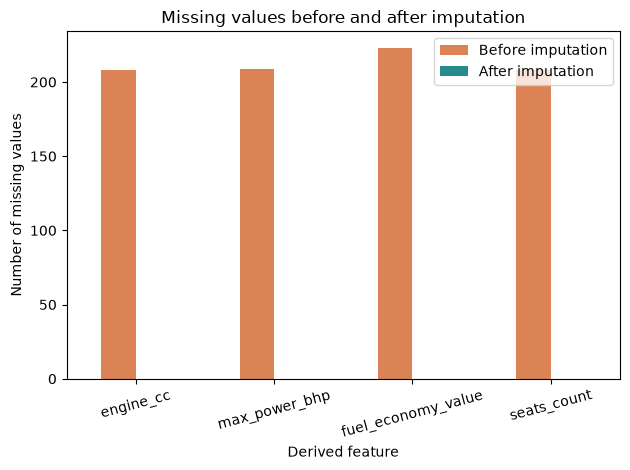

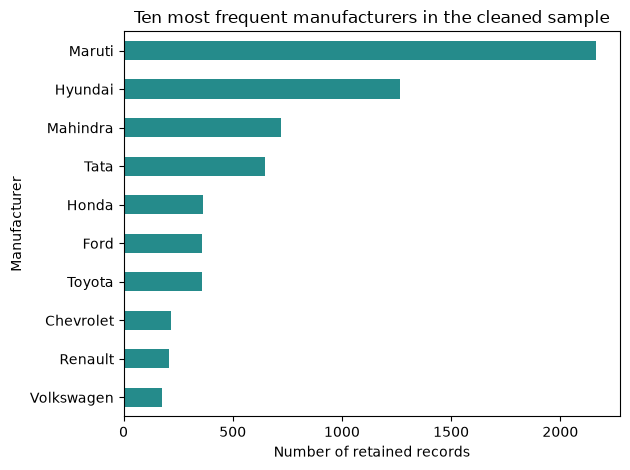

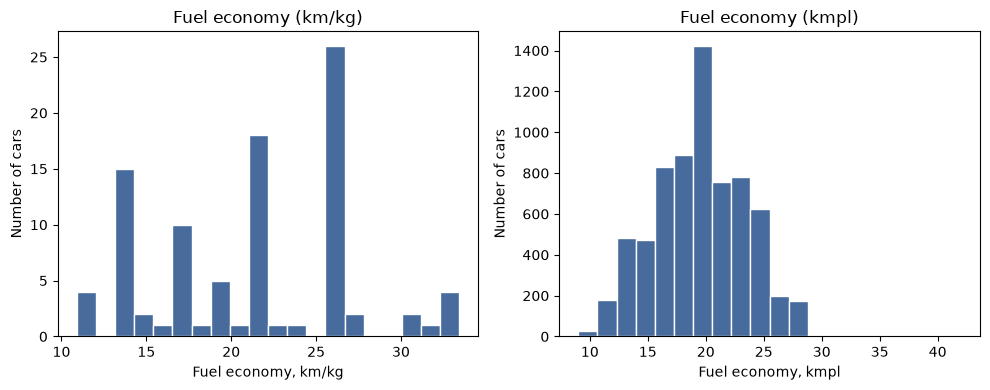

Most frequent manufacturer: Maruti with 2165 records
Missing final numerical values: 0


In [19]:
import matplotlib.pyplot as plt

before_counts = before_imputation[["engine_cc", "max_power_bhp", "fuel_economy_value", "seats"]].isna().sum()
before_counts.index = final_numeric
after_counts = cars_clean[final_numeric].isna().sum()
missing_chart = pd.DataFrame({"Before imputation": before_counts, "After imputation": after_counts})
ax = missing_chart.plot.bar(color=["#dc8355", "#258b8b"], rot=15)
ax.set(title="Missing values before and after imputation", xlabel="Derived feature", ylabel="Number of missing values")
plt.tight_layout()
plt.show()

brand_counts = cars_clean["brand"].value_counts().head(10)
ax = brand_counts.sort_values().plot.barh(color="#258b8b")
ax.set(title="Ten most frequent manufacturers in the cleaned sample", xlabel="Number of retained records", ylabel="Manufacturer")
plt.tight_layout()
plt.show()

units = sorted(cars_clean["fuel_economy_unit"].dropna().unique())
fig, axes = plt.subplots(1, len(units), figsize=(10, 4), squeeze=False)
for ax, unit in zip(axes[0], units):
    values = cars_clean.loc[cars_clean["fuel_economy_unit"].eq(unit), "fuel_economy_value"]
    ax.hist(values, bins=20, color="#466b9c", edgecolor="white")
    ax.set(title=f"Fuel economy ({unit})", xlabel=f"Fuel economy, {unit}", ylabel="Number of cars")
fig.tight_layout()
# fig.savefig(REPORTS / "fuel_economy_by_unit.png", dpi=150)
plt.show()
print("Most frequent manufacturer:", brand_counts.index[0], "with", int(brand_counts.iloc[0]), "records")
print("Missing final numerical values:", int(after_counts.sum()))


## 13. Export, and summarize decisions
These assertions check the intended outcome, including row accounting, unit
separation, positive measurements, integer seats, and manufacturer extraction.
They do not require every original text field to become complete.


In [20]:
# Save Only the Cleaned Dataset

from pathlib import Path

PROCESSED = Path("../data/processed")
PROCESSED.mkdir(parents=True, exist_ok=True)

output_file = PROCESSED / "cars_cleaned.csv"
cars_clean.to_csv(output_file, index=False)

print("Cleaned dataset saved:", output_file.resolve())
print("Rows and columns:", cars_clean.shape)

Cleaned dataset saved: C:\Personal\Projects\cleaning-imputation-outliers\data\processed\cars_cleaned.csv
Rows and columns: (6926, 36)


## 14. Connect to Neon PostgreSQL
1. Open your Neon project and choose **Connect**. Copy the PostgreSQL URL.
2. Copy `.env.example` to `.env` beside this notebook; replace the placeholder.
3. Run this section after installing `requirements.txt`. If you change the URL
   during a session, restart the kernel and Run All so an older environment
   variable cannot take precedence.

The helper uses SQLAlchemy with the explicit psycopg2 driver and SSL. It creates
the assignment's `cardekho_lab` schema and four tables: `runs`, `raw_cars`,
`clean_cars`, and `cleaning_audit`. A database role with schema-creation/write
permission is required. Use a Neon project you are permitted to write to.

`run_id` is based on the source-file hash and cleaning policy version. Repeating
the same batch reuses its data and verifies row counts. New sources/policies
create new batches. Writes are transactional and use primary/foreign keys.
Increment `POLICY_VERSION` whenever cleaning logic changes so results are not
confused with a previously stored batch.
The helper does not replace any existing table or delete any row.

[Neon SQLAlchemy example](https://neon.com/blog/deploy-a-serverless-fastapi-app-with-neon-postgres-and-aws-app-runner-at-any-scale)
and [SQLAlchemy PostgreSQL/SSL documentation](https://docs.sqlalchemy.org/en/20/dialects/postgresql.html).


In [21]:
# Upload the Processed CSV to Neon PostgreSQL

from pathlib import Path
import sys

PROJECT_ROOT = Path("..").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.neon_connect import DatabaseManager

processed_file = PROJECT_ROOT / "data" / "processed" / "cars_cleaned.csv"
processed_cars = pd.read_csv(processed_file)

db = DatabaseManager()

try:
    db.upload_dataframe(
        processed_cars,
        "cardekho_clean",
        if_exists="replace"
    )

    # Verify how many records were stored.
    result = db.fetch_dataframe(
        "SELECT COUNT(*) AS total_rows FROM cardekho_clean"
    )

    assert int(result.loc[0, "total_rows"]) == len(processed_cars)

    display(result)

    # Preview the uploaded data.
    display(
        db.fetch_dataframe(
            "SELECT * FROM cardekho_clean LIMIT 5"
        )
    )

    print("Processed CSV uploaded and row count verified.")

finally:
    db.engine.dispose()

✅ Successfully connected to Neon PostgreSQL database.
✅ Successfully uploaded 6926 rows to 'cardekho_clean'.


,total_rows
0,6926


,source_row,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,...,fuel_economy_value,fuel_economy_unit,economy_invalid_nonpositive,fuel_economy_unit_inferred,engine_cc_imputed,max_power_bhp_imputed,fuel_economy_value_imputed,seats_count,seats_count_imputed,price_iqr_flag
0,1,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,...,23.40,kmpl,False,False,False,False,False,5,False,False
1,2,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,...,21.14,kmpl,False,False,False,False,False,5,False,False
2,3,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,...,17.70,kmpl,False,False,False,False,False,5,False,False
3,4,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,...,23.00,kmpl,False,False,False,False,False,5,False,False
4,5,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,...,16.10,kmpl,False,False,False,False,False,5,False,False


Processed CSV uploaded and row count verified.


## 15. Observations and reflection
The original file contains 8,128 records with five columns containing missing
values. Removing 1,202 exact repeats under the documented listing assumption
leaves 6,926 records; all pass the essential-field checks. String manipulation
separates measurement values from units, retains multiword manufacturers, and
produces numeric engine capacity, power, and fuel economy. Zero placeholders
are treated as missing, and imputation flags distinguish estimated values from
observed ones. The exported cleaning summary gives the exact counts after
deduplication and parsing. Fuel-economy units remain separate. Potential price
outliers are retained because extreme prices alone do not establish an error.

The missing-value chart shows the selected numerical features are complete
after imputation. The manufacturer chart shows which brands are most frequent
in this sample, while the two fuel-economy histograms show distributions in
their respective units. Imputation can reduce variability, so numerical
completeness should not be interpreted as perfect measurement quality.

Neon provides persistent relational storage and allows SQL analysis without
repeating the cleaning step. Raw, clean, audit, and batch tables preserve the
processing lineage. A local run with no URL does not establish that a database
connection works; only the successful upload and read-back output does.

Limitations include historical advertised prices, nonrepresentative listings,
unverified duplicate identities, estimated missing values, and unresolved torque
formatting. These limitations should be considered before later ML work.


# Section 3: Imputation and Missing Values

## **Task 3.1 – Load and Inspect the  Dataset**

### Import Libraries & Load Utility Functions

In [22]:
import sys
import os
import importlib
import pandas as pd
from pathlib import Path
from dotenv import load_dotenv
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sqlalchemy import create_engine, text

sys.path.append("../src")

import imputation_utils
importlib.reload(imputation_utils)

from imputation_utils import (
    read_file,
    inspect_data,
    assess_missing_invalid,
    check_duplicates,
    compare_missing_values,
    impute_missing,
    validate_cleaning,
    upload_to_database
)

### 1.Loading and  Data Inspection

- Checked dataset shape and columns.
- Reviewed sample rows and data types.
- Checked missing values and duplicates.
- Explored summary statistics.

In [23]:
df = read_file("../data/pew_religion.csv")
inspect_data(df)

1. Dataset Shape:
(36918, 17)

2. Column Names:
['P_SUID', 'WEIGHT', 'YEAR_FROM_CODATE', 'BIRTHDECADE', 'GENDER', 'EDUCREC', 'INC_SDT1', 'RACECMB', 'MARITAL', 'RELTRAD', 'RELIMP', 'ATTNDPERRLS', 'PRAY', 'HAPPY', 'PARTY', 'IDEO', 'AGE_ESTIMATED']

3. First 10 Rows:


c:\Personal\Projects\cleaning-imputation-outliers\notebooks\../src\imputation_utils.py:7: DtypeWarning: Columns (16: AGE_ESTIMATED) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,P_SUID,WEIGHT,YEAR_FROM_CODATE,BIRTHDECADE,GENDER,EDUCREC,INC_SDT1,RACECMB,MARITAL,RELTRAD,RELIMP,ATTNDPERRLS,PRAY,HAPPY,PARTY,IDEO,AGE_ESTIMATED
0,10000040.0,4399.707781,2023.0,1990s,A woman,Some college/associate's degree,"$30,000 to less than $40,000",White,Living with a partner,Evangelical Protestant Tradition,Very important,Once a week,Several times a day,Very happy,Republican,Very conservative,28
1,10000060.0,6693.424549,2023.0,1970s,A woman,Master's degree or higher,"$125,000 to less than $150,000",White,Married,Religiously Unaffiliated,Not at all important,Never,Never,Very happy,Democrat,Very liberal,48
2,10000140.0,3080.916226,2024.0,1980s,A woman,College graduate,"$125,000 to less than $150,000",White,Married,Catholic,Very important,Once or twice a month,Once a day,Pretty happy,Independent,Moderate,39
3,10000150.0,5470.685158,2023.0,1960s,A woman,High school or less,DON'T KNOW/REFUSED,White,Married,Religiously Unaffiliated,Not at all important,Never,Never,Not too happy,Republican,Moderate,58
4,10000160.0,2474.921511,2023.0,1970s,A woman,College graduate,"$75,000 to less than $100,000",Black or African-American,Divorced,Historically Black Protestant Tradition,Somewhat important,Seldom,Seldom,Not too happy,Democrat,Liberal,48
5,10000200.0,5220.197875,2024.0,1950s,A woman,Some college/associate's degree,"$30,000 to less than $40,000",Black or African-American,Married,Historically Black Protestant Tradition,Very important,More than once a week,Several times a day,Pretty happy,Democrat,Moderate,69
6,10000240.0,6276.829011,2023.0,1960s,A man,Some college/associate's degree,"$50,000 to less than $75,000",White,Divorced,Evangelical Protestant Tradition,Very important,A few times a year,Seldom,Pretty happy,Independent,Conservative,58
7,10000250.0,7408.343658,2024.0,1980s,A man,College graduate,"$100,000 to less than $125,000",White,Never been married,Religiously Unaffiliated,Not too important,Once or twice a month,Seldom,Not too happy,Independent,Very conservative,39
8,10000280.0,3800.264847,2024.0,1960s,A woman,College graduate,DON'T KNOW/REFUSED,White,Married,Catholic,Somewhat important,Seldom,A few times a week,Very happy,Republican,Moderate,59
9,10000420.0,3901.603222,2023.0,1970s,A woman,College graduate,"$75,000 to less than $100,000",White,Married,Catholic,Not too important,A few times a year,Once a week,Pretty happy,Democrat,Liberal,48



4. Data Types:
P_SUID              float64
WEIGHT              float64
YEAR_FROM_CODATE    float64
BIRTHDECADE             str
GENDER                  str
EDUCREC                 str
INC_SDT1                str
RACECMB                 str
MARITAL                 str
RELTRAD                 str
RELIMP                  str
ATTNDPERRLS             str
PRAY                    str
HAPPY                   str
PARTY                   str
IDEO                    str
AGE_ESTIMATED        object
dtype: object

5. Missing Values:
P_SUID                 1
WEIGHT               370
YEAR_FROM_CODATE       1
BIRTHDECADE            1
GENDER               370
EDUCREC              370
INC_SDT1               1
RACECMB                1
MARITAL                1
RELTRAD                1
RELIMP                 1
ATTNDPERRLS            1
PRAY                   1
HAPPY                370
PARTY                  1
IDEO                   1
AGE_ESTIMATED       6748
dtype: int64

6. Missing Value Percentages:
P_SUI

,P_SUID,WEIGHT,YEAR_FROM_CODATE,BIRTHDECADE,GENDER,EDUCREC,INC_SDT1,RACECMB,MARITAL,RELTRAD,RELIMP,ATTNDPERRLS,PRAY,HAPPY,PARTY,IDEO,AGE_ESTIMATED
count,3.691700e+04,36548.000000,36917.000000,36917,36548,36548,36917,36917,36917,36917,36917,36917,36917,36548,36917,36917,30170
unique,NaN,NaN,NaN,8,5,5,9,6,7,16,5,7,8,4,5,6,25
top,NaN,NaN,NaN,1950s,A woman,Some college/associate's degree,"$150,000 or more",White,Married,Religiously Unaffiliated,Very important,Seldom,Several times a day,Pretty happy,Democrat,Moderate,68
freq,NaN,NaN,NaN,7814,20315,11009,6733,28183,18915,10733,13749,9198,10275,21315,12128,13373,5839
mean,1.108337e+07,6974.734049,2023.136441,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,6.217321e+05,7593.243921,0.343261,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.000004e+07,166.396325,2023.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,1.054501e+07,2594.530893,2023.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.108171e+07,4614.677544,2023.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.162273e+07,8248.323894,2023.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



9. Random Sample Rows:


,P_SUID,WEIGHT,YEAR_FROM_CODATE,BIRTHDECADE,GENDER,EDUCREC,INC_SDT1,RACECMB,MARITAL,RELTRAD,RELIMP,ATTNDPERRLS,PRAY,HAPPY,PARTY,IDEO,AGE_ESTIMATED
3084,10183410.0,1550.313067,2023.0,1950s,A man,Some college/associate's degree,"$50,000 to less than $75,000",White,Married,Evangelical Protestant Tradition,Very important,More than once a week,Several times a day,Very happy,Independent,Moderate,68
3502,10209020.0,11692.984030,2024.0,1950s,A man,High school or less,"$40,000 to less than $50,000",White,Never been married,Orthodox Christian,Very important,More than once a week,Several times a day,Very happy,Independent,Very conservative,69
12641,10747240.0,3420.249691,2023.0,1950s,A woman,Some college/associate's degree,"$30,000 to less than $40,000",White,Married,Mainline Protestant Tradition,Very important,A few times a year,Several times a day,Pretty happy,Independent,Moderate,68
36117,12111200.0,52199.959420,2023.0,1990s,A woman,Some college/associate's degree,"$75,000 to less than $100,000",Black or African-American,Never been married,Religiously Unaffiliated,Not at all important,Never,Never,Very happy,Democrat,Very liberal,28.0
20115,11180440.0,6519.481711,2023.0,1980s,A woman,Some college/associate's degree,"$75,000 to less than $100,000",DON'T KNOW/REFUSED,Living with a partner,Religiously Unaffiliated,Not at all important,Seldom,Never,Pretty happy,Independent,Liberal,38


Empty rows: 1


## **Task 3.2 – Assess Missing and Invalid Values**

## Task 2: Missing and Invalid Values

- Checked missing values and their percentages.
- Counted valid observations using `notnull()`.
- Checked `WEIGHT`, `YEAR_FROM_CODATE`, and `AGE_ESTIMATED` for invalid numeric values.
- Converted selected columns to numeric data types.

In [24]:
numeric_cols = ["WEIGHT", "YEAR_FROM_CODATE", "AGE_ESTIMATED"]

df = assess_missing_invalid(df, numeric_cols)

1. Missing Values:
P_SUID                 1
WEIGHT               370
YEAR_FROM_CODATE       1
BIRTHDECADE            1
GENDER               370
EDUCREC              370
INC_SDT1               1
RACECMB                1
MARITAL                1
RELTRAD                1
RELIMP                 1
ATTNDPERRLS            1
PRAY                   1
HAPPY                370
PARTY                  1
IDEO                   1
AGE_ESTIMATED       6748
dtype: int64

2. Missing Value Percentages:
P_SUID               0.00
WEIGHT               1.00
YEAR_FROM_CODATE     0.00
BIRTHDECADE          0.00
GENDER               1.00
EDUCREC              1.00
INC_SDT1             0.00
RACECMB              0.00
MARITAL              0.00
RELTRAD              0.00
RELIMP               0.00
ATTNDPERRLS          0.00
PRAY                 0.00
HAPPY                1.00
PARTY                0.00
IDEO                 0.00
AGE_ESTIMATED       18.28
dtype: float64

3. Valid Observations:
P_SUID              36917
WEIGH

## **Task 3.3 – Check Duplicates**
- Found 10 duplicate rows.
- Removed duplicate records.
- Final dataset: 36,908 rows and 17 columns.


In [25]:
check_duplicates(df)

df_clean = df.drop_duplicates().reset_index(drop=True)

print("Duplicates after:", df_clean.duplicated().sum())

1. Number of Duplicate Rows: 10

2. Duplicate Records:


,P_SUID,WEIGHT,YEAR_FROM_CODATE,BIRTHDECADE,GENDER,EDUCREC,INC_SDT1,RACECMB,MARITAL,RELTRAD,RELIMP,ATTNDPERRLS,PRAY,HAPPY,PARTY,IDEO,AGE_ESTIMATED
3199,10191460.0,5477.553927,2023.0,1980s,A woman,Some college/associate's degree,"$75,000 to less than $100,000",White,Married,Religiously Unaffiliated,Somewhat important,Once or twice a month,A few times a week,Pretty happy,Republican,Conservative,38.0
6405,10381060.0,7463.613554,2023.0,1950s,A woman,Some college/associate's degree,DON'T KNOW/REFUSED,Black or African-American,Married,Evangelical Protestant Tradition,Very important,More than once a week,Once a day,Pretty happy,Democrat,Moderate,68.0
9927,10586300.0,2785.696049,2023.0,1980s,A woman,College graduate,"$40,000 to less than $50,000",White,Never been married,Religiously Unaffiliated,Not too important,Never,Never,Not too happy,Independent,Very liberal,38.0
13183,10780210.0,1307.265392,2023.0,1990s,A man,Master's degree or higher,"$150,000 or more",White,Married,Religiously Unaffiliated,Not at all important,Seldom,Never,Pretty happy,Democrat,Liberal,28.0
18977,11111270.0,3055.283136,2023.0,1940s or earlier,A woman,College graduate,DON'T KNOW/REFUSED,Black or African-American,Widowed,Evangelical Protestant Tradition,Very important,A few times a year,Once a day,Pretty happy,Democrat,Liberal,NaN
23501,11378720.0,5586.344849,2023.0,1960s,A man,College graduate,DON'T KNOW/REFUSED,White,Married,Catholic,Very important,Once a week,Several times a day,Very happy,Republican,Conservative,58.0
26655,11562620.0,7336.060935,2023.0,1950s,A man,High school or less,"$75,000 to less than $100,000",White,Married,Catholic,Very important,Once a week,Several times a day,Pretty happy,Republican,Conservative,68.0
28978,11695610.0,1625.181698,2023.0,1950s,A man,College graduate,"$50,000 to less than $75,000",White,Living with a partner,Evangelical Protestant Tradition,Somewhat important,Seldom,Several times a day,Not too happy,Democrat,Moderate,68.0
33139,11939370.0,2229.816529,2024.0,1940s or earlier,A man,College graduate,"$50,000 to less than $75,000",White,Married,Religiously Unaffiliated,Not too important,Never,Seldom,Very happy,Independent,Moderate,NaN
36882,12156460.0,2669.049048,2023.0,1980s,A man,Some college/associate's degree,"$75,000 to less than $100,000",White,Married,Mainline Protestant Tradition,Very important,Once or twice a month,Once a week,Very happy,Republican,Moderate,38.0



Duplicates removed successfully.

3. Dataset Shape: (36908, 17)
Duplicates after: 0


### **Task 3.4 – Compare Missing-Value Strategies**

#### Creating a  copy of my dataframe and export to up_pew_religion.csv

In [26]:

import os

# Copy the dataset after duplicate removal
df_copy = df_clean.copy()

# Export cleaned copy
df_copy.to_csv("../data/up_pew_religion.csv", index=False)

# Load the copy
df_miss = pd.read_csv("../data/up_pew_religion.csv")

# Verify duplicates
print("Duplicates:", df_miss.duplicated().sum())



Duplicates: 0


## **Task 3.5 – Use Visualization to Support an Imputation Decision**


### Estimated Age Analysis

- Valid observations: 30,169
- Missing values: 6,749
- Mean age: 49.54
- Median age: 48
- Age range: 18–69

**Finding:** The mean and median are close, suggesting the age distribution may be relatively balanced. A histogram will help confirm this.

In [27]:
print("Age Statistics:")
print(df_miss["AGE_ESTIMATED"].describe())

print("\nMissing Values:")
print(df_miss["AGE_ESTIMATED"].isnull().sum())

Age Statistics:
count    30161.000000
mean        49.537681
std         15.352591
min         18.000000
25%         38.000000
50%         48.000000
75%         68.000000
max         69.000000
Name: AGE_ESTIMATED, dtype: float64

Missing Values:
6747


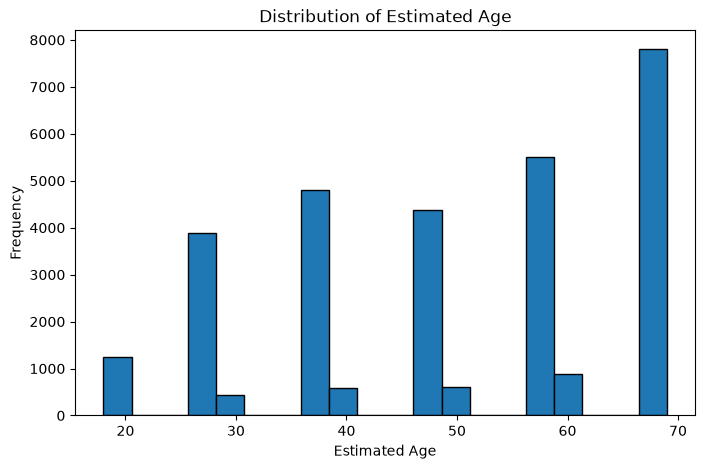

In [28]:
plt.figure(figsize=(8, 5))

plt.hist(df_miss["AGE_ESTIMATED"].dropna(), bins=20, edgecolor="black")

plt.title("Distribution of Estimated Age")
plt.xlabel("Estimated Age")
plt.ylabel("Frequency")

plt.show()

### Distribution Analysis of Estimated Age based on above graph

The histogram of **Estimated Age** shows a **negatively skewed (left-skewed) distribution**, with more observations concentrated at higher ages and fewer at lower ages.

Since the distribution is not symmetric, the **median** is a better choice than the mean for imputing missing values.

The median is less affected by extreme values and provides a more robust representation of the central tendency.

## Task 3.6 – Apply SimpleImputer
we used **SimpleImputer** with the **median strategy** to fill missing values in the Estimated Age column.

- **fit()** calculates the median.
- **transform()** fills missing values with the median.
- **fit_transform()** combines both steps.

we checked the column afterward to confirm that no missing values remained.

In [29]:
df_miss = impute_missing(df_miss, 'AGE_ESTIMATED')
print(df_miss['AGE_ESTIMATED'].isnull().sum())

0


### Plotting the graph again

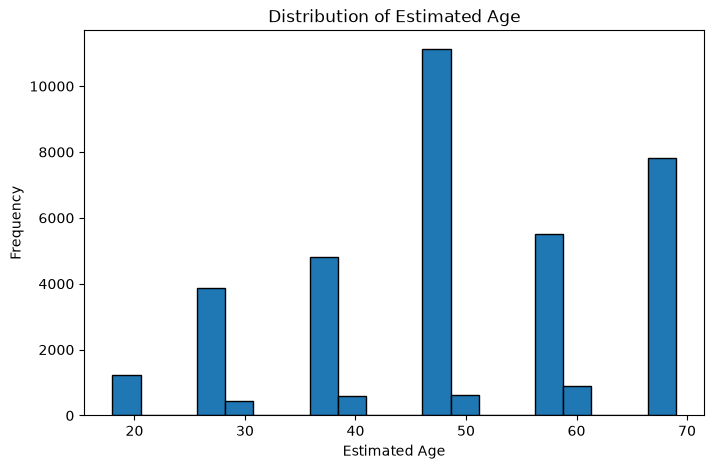

In [30]:
plt.figure(figsize=(8, 5))

plt.hist(df_miss["AGE_ESTIMATED"].dropna(), bins=20, edgecolor="black")

plt.title("Distribution of Estimated Age")
plt.xlabel("Estimated Age")
plt.ylabel("Frequency")

plt.show()

### Checking median and missing values on the current column

In [31]:
print("Median:", df_miss["AGE_ESTIMATED"].median())
print("Missing values:", df_miss["AGE_ESTIMATED"].isnull().sum())

Median: 48.0
Missing values: 0


## **Task 3.7 – Validate the Cleaned Dataset**


=== Shape ===
Before: (36918, 17)
After: (36908, 17)

=== Missing Values ===
Before:
 P_SUID                 1
WEIGHT               370
YEAR_FROM_CODATE       1
BIRTHDECADE            1
GENDER               370
EDUCREC              370
INC_SDT1               1
RACECMB                1
MARITAL                1
RELTRAD                1
RELIMP                 1
ATTNDPERRLS            1
PRAY                   1
HAPPY                370
PARTY                  1
IDEO                   1
AGE_ESTIMATED       6749
dtype: int64
After:
 P_SUID                1
WEIGHT              370
YEAR_FROM_CODATE      1
BIRTHDECADE           1
GENDER              370
EDUCREC             370
INC_SDT1              1
RACECMB               1
MARITAL               1
RELTRAD               1
RELIMP                1
ATTNDPERRLS           1
PRAY                  1
HAPPY               370
PARTY                 1
IDEO                  1
AGE_ESTIMATED         0
dtype: int64

=== Duplicates ===
Before: 10
After: 0

=== De

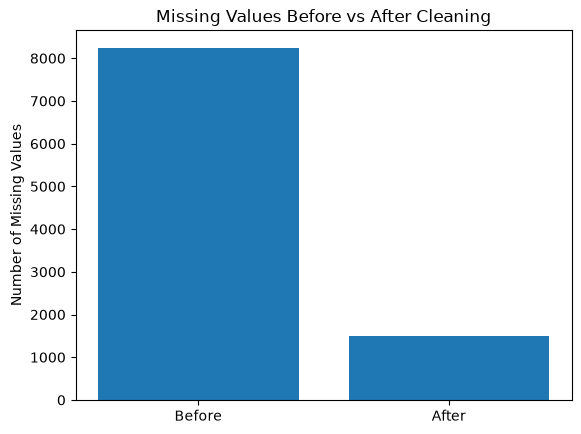

In [32]:
# Call the method
validate_cleaning(df, df_miss)

### Task 3.8 – Data Cleaning Reflection

**1. Main Data-Quality Problems**

The main problems were missing values, duplicate rows, and some invalid values.

**2. Missing Values**

We found 6,749 missing values in the `AGE_ESTIMATED` column before cleaning.

**3. Dropping Rows**

We lost 7,930 rows when we dropped rows with missing values. This means we could lose useful data that we might need later.

**4. Dropping Columns**

Some columns contain useful information, and removing them could affect the analysis.

**5. Mean Imputation**

Mean is a good choice when the data is approximately symmetric and does not have extreme values.

**6. Median Imputation**

Median is better when the data is skewed or has outliers because it is less affected by extreme values.

**7. Mode Imputation**

Mode is useful for categorical columns like `GENDER` because it fills missing values with the most common value.

**8. SimpleImputer vs fillna()**

`SimpleImputer` uses `fit()` and `transform()` to calculate and fill missing values. `fillna()` fills missing values directly.

**9. Changes in Dataset Statistics**

The changes were not very large. We removed 10 duplicate rows and filled the missing ages using the median. The mean and standard deviation changed slightly, but the median stayed at 48.

**10. Cleaning Decisions for an ML Pipeline**

We would remove duplicates and use median for skewed numerical columns and mode for categorical columns. We would also use `SimpleImputer` because it makes the cleaning process easier and more consistent.

# Upload Cleaned Data to PostgreSQL

We connected to our Neon PostgreSQL database and uploaded the cleaned DataFrame (`df_miss`) into a new table called `pew_religion_cleaned`.

We also checked the number of rows in the database to make sure the data was uploaded successfully.

# Reading From Database 

In [33]:
from dotenv import load_dotenv
from sqlalchemy import create_engine

# Load environment variables
load_dotenv()

# Get database connection string
DATABASE_URL = os.getenv("DATABASE_URL")

# Create database engine
engine = create_engine(DATABASE_URL)

# Read data from database
df_db = pd.read_sql(
    "SELECT * FROM pew_religion_cleaned",
    engine
)

print("Total records:", len(df_db))

Total records: 36908


# Graph 1 – Religious Affiliation

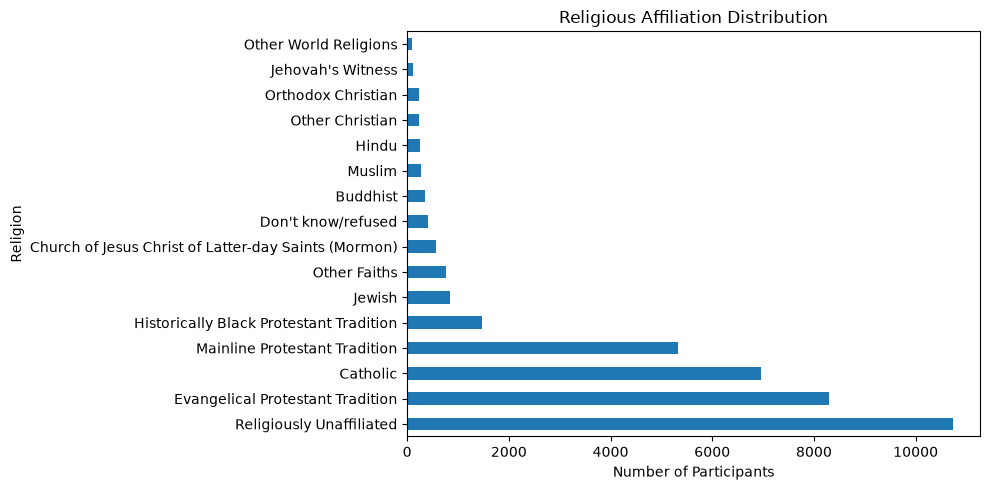

In [34]:
plt.figure(figsize=(10, 5))

df_db['RELTRAD'].value_counts().plot(kind='barh')

plt.title('Religious Affiliation Distribution')
plt.xlabel('Number of Participants')
plt.ylabel('Religion')

plt.tight_layout()
plt.show()

# Graph2: Religion Importance by Birth Decade

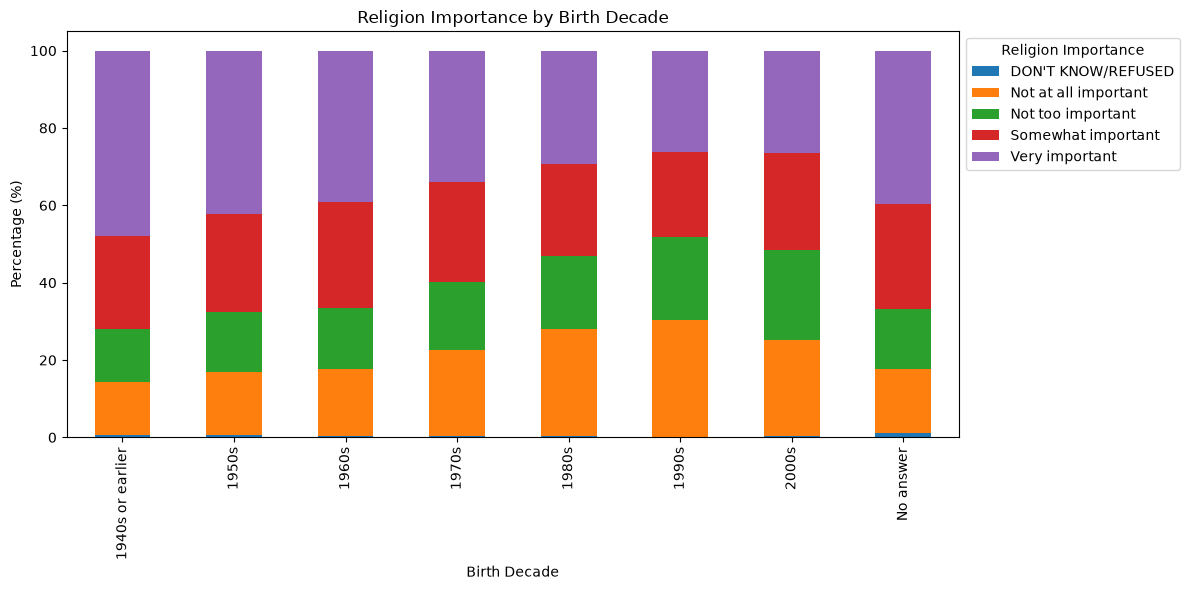

In [35]:
data = pd.crosstab(
    df_db['BIRTHDECADE'],
    df_db['RELIMP'],
    normalize='index'
) * 100

data.plot(kind='bar', stacked=True, figsize=(12, 6))

plt.title('Religion Importance by Birth Decade')
plt.xlabel('Birth Decade')
plt.ylabel('Percentage (%)')
plt.legend(title='Religion Importance', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

# Graph 3: Happiness by Religious Importance

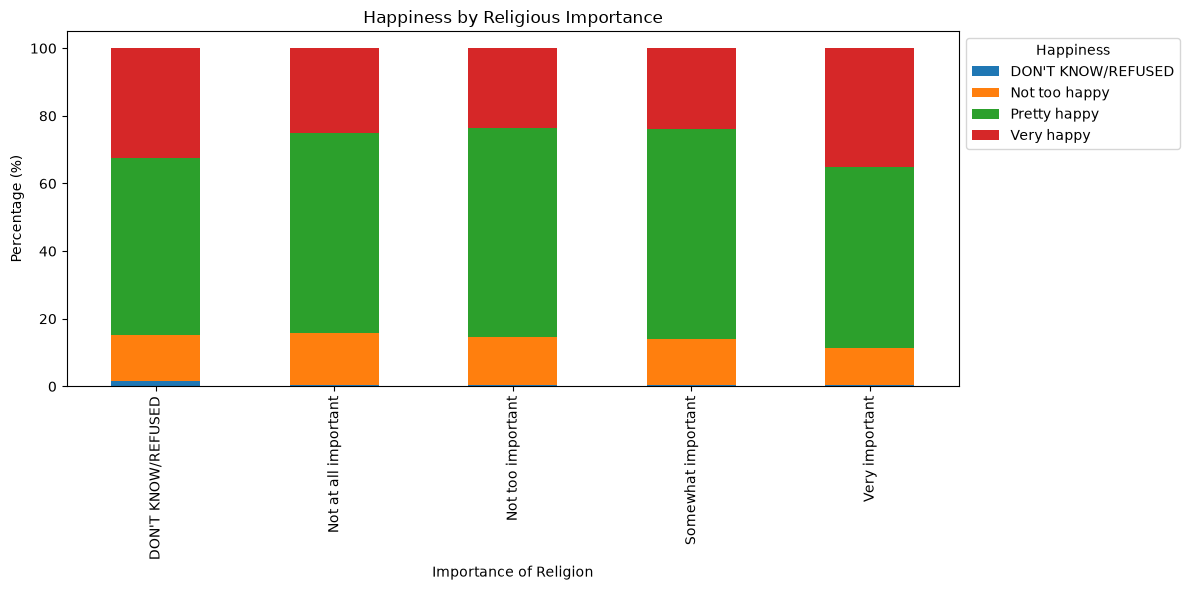

In [36]:
data = pd.crosstab(
    df_db['RELIMP'],
    df_db['HAPPY'],
    normalize='index'
) * 100

data.plot(kind='bar', stacked=True, figsize=(12, 6))

plt.title('Happiness by Religious Importance')
plt.xlabel('Importance of Religion')
plt.ylabel('Percentage (%)')
plt.legend(title='Happiness', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

# Graph 4: Income by Religious Affiliation — Heatmap

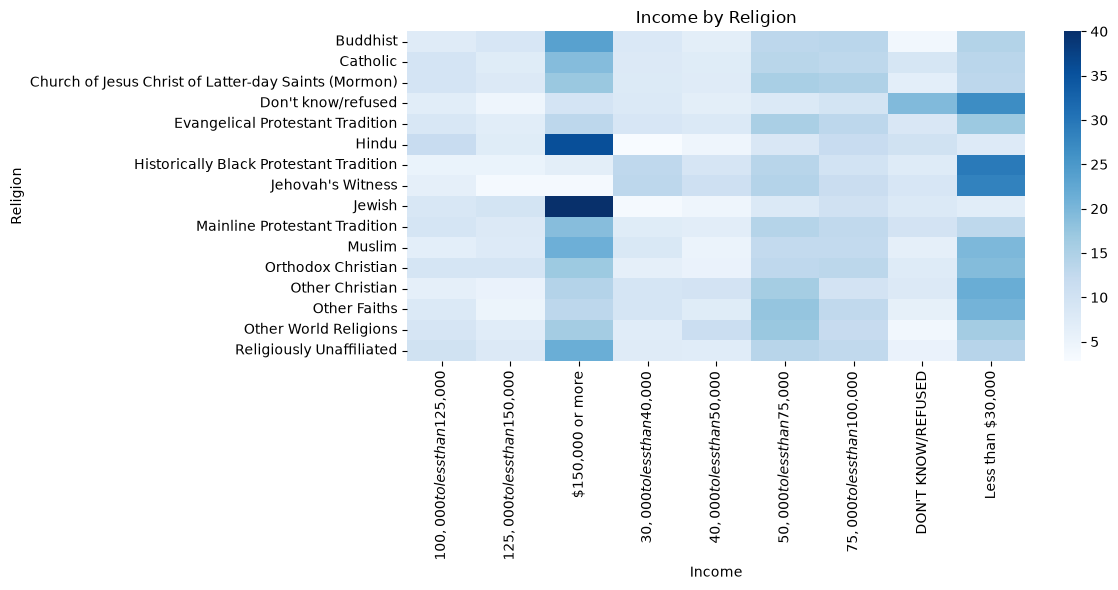

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.crosstab(
    df_db['RELTRAD'],
    df_db['INC_SDT1'],
    normalize='index'
) * 100

plt.figure(figsize=(12, 6))
sns.heatmap(data, cmap='Blues')

plt.title('Income by Religion')
plt.xlabel('Income')
plt.ylabel('Religion')
plt.tight_layout()
plt.show()

# Section 4: Outlier Detection & Feature Engineering

Student: Juan Camilo Chirivi 

ID: 9115141


## Data Source and Use Case

**Dataset:** Bank Marketing – `bank-full.csv`  
**Source:** UCI Machine Learning Repository  
**Official page:** https://archive.ics.uci.edu/dataset/222/bank+marketing  

The data comes from direct marketing campaigns of a Portuguese banking institution. The campaigns were based mainly on phone calls, and the target variable `y` indicates whether the client subscribed to a term deposit.


In [38]:
# Imports and project paths

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

# Find the project root whether the notebook is launched from /notebooks or from the root.
cwd = Path.cwd()

if (cwd / "data" / "bank-full.csv").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "bank-full.csv").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError(
        "Could not find data/bank-full.csv. "
        "Run the notebook from the project root or the notebooks folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "bank-full.csv"

# Allow imports from src/
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.neon_connect import DatabaseManager

print("Project root:", PROJECT_ROOT)
print("Data path:", DATA_PATH)

Project root: c:\Personal\Projects\cleaning-imputation-outliers
Data path: c:\Personal\Projects\cleaning-imputation-outliers\data\bank-full.csv


## Load and Validate the Original CSV

This first local load is used to validate the file before sending it to Neon.

In [39]:
# Load the original UCI file
bank_csv = pd.read_csv(DATA_PATH, sep=";")

print("Shape:", bank_csv.shape)
print("\nColumns:")
print(bank_csv.columns.tolist())

display(bank_csv.head())

Shape: (45211, 17)

Columns:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [40]:
# Basic source validation

print("Rows:", len(bank_csv))
print("Columns:", bank_csv.shape[1])
print("Duplicate rows:", bank_csv.duplicated().sum())
print("Missing values:", int(bank_csv.isna().sum().sum()))

# The project requires at least 10,000 records.
assert len(bank_csv) >= 10_000, "The dataset does not meet the 10,000-row requirement."

display(bank_csv.dtypes.to_frame("dtype"))

Rows: 45211
Columns: 17
Duplicate rows: 0
Missing values: 0


,dtype
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64


### Initial observation

The file contains 45,211 rows and 17 columns. The downloaded version does not contain standard `NaN` values or exact duplicate rows.

Some categorical columns contain the text `unknown`. This is not treated as a numeric outlier. For this use case, those values are kept because the main focus is numeric outlier detection and Feature Engineering.

In [41]:
# Count 'unknown' values in categorical columns without changing the dataset

categorical_columns = bank_csv.select_dtypes(include="object").columns

unknown_summary = pd.DataFrame({
    "column": categorical_columns,
    "unknown_count": [
        bank_csv[col].astype(str).str.lower().eq("unknown").sum()
        for col in categorical_columns
    ]
})

unknown_summary = unknown_summary[
    unknown_summary["unknown_count"] > 0
].reset_index(drop=True)

display(unknown_summary)

C:\Users\ricar\AppData\Local\Temp\ipykernel_29936\2731619218.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = bank_csv.select_dtypes(include="object").columns


,column,unknown_count
0,job,288
1,education,1857
2,contact,13020
3,poutcome,36959


## Upload Raw Data to Neon PostgreSQL

In [42]:
# Connect to the shared Neon database

db = DatabaseManager()

RAW_TABLE = "bank_marketing_raw"

# Set this to False after the raw table has already been uploaded
# and you only want to read it from Neon.
UPLOAD_RAW_TO_NEON = True

if UPLOAD_RAW_TO_NEON:
    db.upload_dataframe(
        bank_csv,
        table_name=RAW_TABLE,
        if_exists="replace"
    )

# From this point forward, use the database copy for the analysis.
bank = db.fetch_dataframe(
    f'SELECT * FROM "{RAW_TABLE}"'
)

print("Rows read from Neon:", len(bank))
display(bank.head())

✅ Successfully connected to Neon PostgreSQL database.
✅ Successfully uploaded 45211 rows to 'bank_marketing_raw'.
Rows read from Neon: 45211


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## Focused Exploratory Data Analysis (EDA)

The main numeric features selected are:

- `age`
- `balance`
- `duration`
- `campaign`

Other numeric fields require special interpretation. For example, `pdays` contains a special negative value and `previous` contains many zeros, so applying a generic outlier rule to them could be misleading.

The goal is not to label every unusual value as an error. The goal is to identify unusual observations and then interpret them.

In [43]:
# General dataset inspection

print("Shape:", bank.shape)
print("\nData types:")
display(bank.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(bank.isna().sum().to_frame("missing_values"))

print("\nDuplicate rows:", bank.duplicated().sum())

print("\nNumeric descriptive statistics:")
display(bank.describe().T)

Shape: (45211, 17)

Data types:


,dtype
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64



Missing values:


,missing_values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Duplicate rows: 0

Numeric descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [44]:
# Numeric features selected for outlier analysis

OUTLIER_FEATURES = [
    "age",
    "balance",
    "duration",
    "campaign"
]

numeric_summary = pd.DataFrame({
    "mean": bank[OUTLIER_FEATURES].mean(),
    "median": bank[OUTLIER_FEATURES].median(),
    "std": bank[OUTLIER_FEATURES].std(),
    "min": bank[OUTLIER_FEATURES].min(),
    "max": bank[OUTLIER_FEATURES].max(),
    "skewness": bank[OUTLIER_FEATURES].skew()
})

display(numeric_summary.round(2))

,mean,median,std,min,max,skewness
age,40.94,39.0,10.62,18,95,0.68
balance,1362.27,448.0,3044.77,-8019,102127,8.36
duration,258.16,180.0,257.53,0,4918,3.14
campaign,2.76,2.0,3.10,1,63,4.90


### EDA interpretation

`balance`, `duration`, and `campaign` are strongly right-skewed. Their maximum values are much larger than their medians.

This is important because:

- **Z-Score** is based on the mean and standard deviation and is more appropriate when a distribution is reasonably close to normal.
- **IQR** is based on quartiles and is more robust when data is skewed.

Because this dataset contains skewed numeric variables, it is useful to compare both methods instead of assuming that one method is always correct.

## Z-Score Outlier Detection

The Z-Score measures how many standard deviations a value is from the mean.

\[
z = \frac{x - \mu}{\sigma}
\]

Where:

- `x` = observation
- `μ` = mean
- `σ` = standard deviation

For this exercise, a value is flagged as a potential outlier when:

\[
|z| > 3
\]

This means the observation is more than three standard deviations away from the mean.

In [45]:
# Z-Score outlier detection
# The calculation is kept in the notebook so the method is visible and explainable.

Z_THRESHOLD = 3

zscore_masks = {}
zscore_rows = []

for feature in OUTLIER_FEATURES:
    mean_value = bank[feature].mean()
    std_value = bank[feature].std(ddof=0)

    # Calculate the Z-Score for every row.
    z_scores = (bank[feature] - mean_value) / std_value

    # Flag values farther than 3 standard deviations from the mean.
    outlier_mask = z_scores.abs() > Z_THRESHOLD

    zscore_masks[feature] = outlier_mask

    zscore_rows.append({
        "feature": feature,
        "mean": mean_value,
        "std": std_value,
        "z_threshold": Z_THRESHOLD,
        "outlier_count": int(outlier_mask.sum()),
        "outlier_percent": outlier_mask.mean() * 100
    })

zscore_summary = pd.DataFrame(zscore_rows)

display(zscore_summary.round(2))

,feature,mean,std,z_threshold,outlier_count,outlier_percent
0,age,40.94,10.62,3,381,0.84
1,balance,1362.27,3044.73,3,745,1.65
2,duration,258.16,257.52,3,963,2.13
3,campaign,2.76,3.10,3,840,1.86


In [46]:
# Show examples of the most extreme Z-Scores for balance

balance_mean = bank["balance"].mean()
balance_std = bank["balance"].std(ddof=0)

balance_z = (
    (bank["balance"] - balance_mean) / balance_std
)

balance_z_examples = bank[
    ["age", "job", "balance", "duration", "campaign", "y"]
].copy()

balance_z_examples["balance_zscore"] = balance_z

display(
    balance_z_examples
    .loc[balance_z.abs() > Z_THRESHOLD]
    .sort_values("balance_zscore", key=abs, ascending=False)
    .head(10)
)

,age,job,balance,duration,campaign,y,balance_zscore
39989,51,management,102127,90,1,no,33.094776
26227,59,management,98417,145,5,no,31.876278
42558,84,retired,81204,679,1,yes,26.222907
43393,84,retired,81204,390,1,yes,26.222907
41693,60,retired,71188,205,1,no,22.933291
19785,56,management,66721,442,2,no,21.466167
21192,52,blue-collar,66653,109,3,no,21.443833
19420,59,admin.,64343,45,4,no,20.685146
41374,32,entrepreneur,59649,69,2,no,19.143466
12926,56,blue-collar,58932,339,2,no,18.907978


### Z-Score interpretation

With this dataset, Z-Score identifies relatively extreme observations, but the method can be influenced by skewed distributions.

For example, a very high bank balance may be statistically unusual while still being a valid customer value. Therefore, the result is treated as a **flag for investigation**, not an automatic deletion rule.

## IQR Outlier Detection

The IQR method uses quartiles instead of the mean and standard deviation.

\[
IQR = Q3 - Q1
\]

The typical limits are:

\[
Lower = Q1 - 1.5(IQR)
\]

\[
Upper = Q3 + 1.5(IQR)
\]

Any value below the lower bound or above the upper bound is flagged as a potential outlier.

Because IQR is based on quartiles, it is usually more robust than Z-Score for skewed distributions.

In [47]:
# IQR outlier detection
# The thresholds are calculated independently for each feature.

iqr_masks = {}
iqr_bounds = {}
iqr_rows = []

for feature in OUTLIER_FEATURES:
    q1 = bank[feature].quantile(0.25)
    q3 = bank[feature].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)

    outlier_mask = (
        (bank[feature] < lower_bound)
        | (bank[feature] > upper_bound)
    )

    iqr_masks[feature] = outlier_mask
    iqr_bounds[feature] = {
        "lower": lower_bound,
        "upper": upper_bound
    }

    iqr_rows.append({
        "feature": feature,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": int(outlier_mask.sum()),
        "outlier_percent": outlier_mask.mean() * 100
    })

iqr_summary = pd.DataFrame(iqr_rows)

display(iqr_summary.round(2))

,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percent
0,age,33.0,48.0,15.0,10.5,70.5,487,1.08
1,balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46
2,duration,103.0,319.0,216.0,-221.0,643.0,3235,7.16
3,campaign,1.0,3.0,2.0,-2.0,6.0,3064,6.78


In [48]:
# Show some IQR outliers for balance

balance_lower = iqr_bounds["balance"]["lower"]
balance_upper = iqr_bounds["balance"]["upper"]

print("Balance lower bound:", balance_lower)
print("Balance upper bound:", balance_upper)

display(
    bank.loc[
        iqr_masks["balance"],
        ["age", "job", "balance", "duration", "campaign", "y"]
    ]
    .sort_values("balance", ascending=False)
    .head(10)
)

Balance lower bound: -1962.0
Balance upper bound: 3462.0


,age,job,balance,duration,campaign,y
39989,51,management,102127,90,1,no
26227,59,management,98417,145,5,no
43393,84,retired,81204,390,1,yes
42558,84,retired,81204,679,1,yes
41693,60,retired,71188,205,1,no
19785,56,management,66721,442,2,no
21192,52,blue-collar,66653,109,3,no
19420,59,admin.,64343,45,4,no
41374,32,entrepreneur,59649,69,2,no
12926,56,blue-collar,58932,339,2,no


## Compare Z-Score and IQR

The two methods are expected to produce different results because they use different definitions of an unusual value.

- Z-Score depends on the **mean and standard deviation**.
- IQR depends on the **middle 50% of the distribution**.
- Highly skewed data can make the methods disagree substantially.

In [49]:
# Compare outlier counts from both methods

comparison = (
    zscore_summary[
        ["feature", "outlier_count", "outlier_percent"]
    ]
    .rename(columns={
        "outlier_count": "zscore_outliers",
        "outlier_percent": "zscore_percent"
    })
    .merge(
        iqr_summary[
            ["feature", "outlier_count", "outlier_percent"]
        ].rename(columns={
            "outlier_count": "iqr_outliers",
            "outlier_percent": "iqr_percent"
        }),
        on="feature"
    )
)

display(comparison.round(2))

,feature,zscore_outliers,zscore_percent,iqr_outliers,iqr_percent
0,age,381,0.84,487,1.08
1,balance,745,1.65,4729,10.46
2,duration,963,2.13,3235,7.16
3,campaign,840,1.86,3064,6.78


### Comparison interpretation

For this `bank-full.csv` file, IQR identifies more potential outliers than Z-Score for the strongly skewed variables.

Expected counts from this dataset are approximately:

| Feature | Z-Score | IQR |
|---|---:|---:|
| age | 381 | 487 |
| balance | 745 | 4,729 |
| duration | 963 | 3,235 |
| campaign | 840 | 3,064 |

The large difference for `balance`, `duration`, and `campaign` is a good example of why the distribution shape matters. IQR is more sensitive to observations outside the central range, while Z-Score can be affected by the same extreme values that increase the mean and standard deviation.

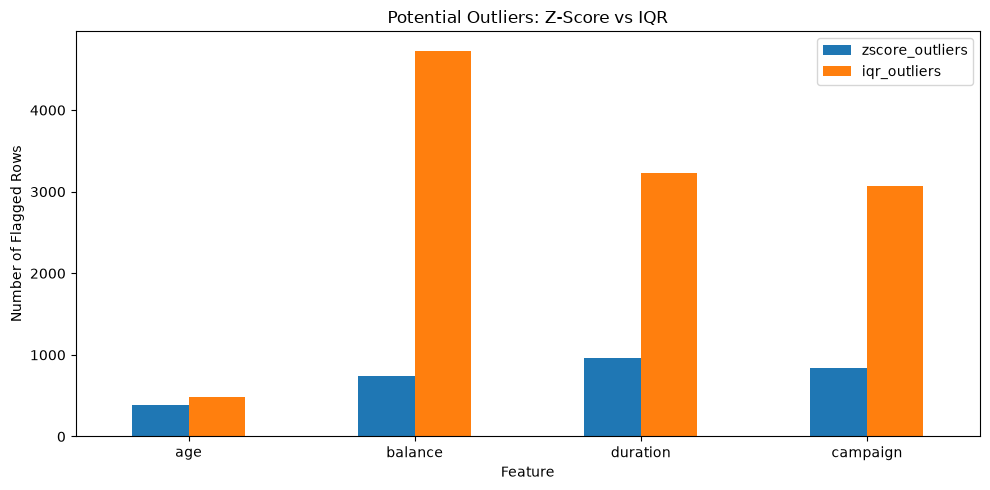

In [50]:
# Visual comparison of detected outlier counts

comparison_plot = comparison.set_index("feature")[
    ["zscore_outliers", "iqr_outliers"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Potential Outliers: Z-Score vs IQR")
plt.xlabel("Feature")
plt.ylabel("Number of Flagged Rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Outlier Treatment Decision

The detected observations are **not automatically removed**.

There is no evidence in the source file that a high bank balance, long call duration, high campaign count, or older customer is necessarily a data-entry error.

For this project:

1. The original rows are retained.
2. IQR outlier flags are added as new features.
3. Skewed variables receive transformed versions that reduce the influence of extreme values.
4. The original numeric columns are preserved for traceability.
º

## Feature Engineering

Feature Engineering help us to create new variables from existing data so the dataset can represent useful patterns more clearly.

The following features are created:

### `age_group`
Converts numeric age into understandable age categories.

### `was_previously_contacted`
Indicates whether the client had a previous campaign contact.

### `total_contacts`
Combines contacts in the current campaign and previous campaigns.

### IQR outlier flags
Creates a binary feature for each selected numeric variable.

### Transformed numeric features
Highly skewed variables receive transformed versions:

- `balance_signed_log`
- `duration_log`
- `campaign_log`

A signed logarithm is used for `balance` because balances can be negative.

In [51]:
# Create the processed dataset without overwriting the original dataframe

bank_processed = bank.copy()

# ---------------------------------------------------------
# 1. Age group
# ---------------------------------------------------------
bank_processed["age_group"] = pd.cut(
    bank_processed["age"],
    bins=[17, 29, 44, 59, np.inf],
    labels=[
        "18-29",
        "30-44",
        "45-59",
        "60+"
    ]
)

# ---------------------------------------------------------
# 2. Previous contact flag
# ---------------------------------------------------------
bank_processed["was_previously_contacted"] = (
    bank_processed["previous"] > 0
).astype(int)

# ---------------------------------------------------------
# 3. Total number of campaign contacts
# ---------------------------------------------------------
bank_processed["total_contacts"] = (
    bank_processed["campaign"]
    + bank_processed["previous"]
)

# ---------------------------------------------------------
# 4. IQR outlier flags
# ---------------------------------------------------------
for feature in OUTLIER_FEATURES:
    bank_processed[f"{feature}_iqr_outlier"] = (
        iqr_masks[feature].astype(int)
    )

# Number of selected features where the row was flagged by IQR
flag_columns = [
    f"{feature}_iqr_outlier"
    for feature in OUTLIER_FEATURES
]

bank_processed["outlier_flag_count"] = (
    bank_processed[flag_columns].sum(axis=1)
)

# ---------------------------------------------------------
# 5. Transform skewed variables
# ---------------------------------------------------------

# Signed log keeps the sign of negative balances.
bank_processed["balance_signed_log"] = (
    np.sign(bank_processed["balance"])
    * np.log1p(np.abs(bank_processed["balance"]))
)

# duration and campaign are non-negative, so log1p is enough.
bank_processed["duration_log"] = np.log1p(
    bank_processed["duration"]
)

bank_processed["campaign_log"] = np.log1p(
    bank_processed["campaign"]
)

display(bank_processed.head())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,age_group,was_previously_contacted,total_contacts,age_iqr_outlier,balance_iqr_outlier,duration_iqr_outlier,campaign_iqr_outlier,outlier_flag_count,balance_signed_log,duration_log,campaign_log
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,45-59,0,1,0,0,0,0,0,7.670429,5.568345,0.693147
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,30-44,0,1,0,0,0,0,0,3.401197,5.023881,0.693147
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,30-44,0,1,0,0,0,0,0,1.098612,4.343805,0.693147
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,45-59,0,1,0,0,0,0,0,7.317876,4.532599,0.693147
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,30-44,0,1,0,0,0,0,0,0.693147,5.293305,0.693147


### Why use log transformations?

Extreme values can make a numeric distribution very skewed.

`log1p(x)` compresses large values more than small values. This can reduce the influence of extreme observations while keeping every row.

For `balance`, a normal logarithm cannot be used directly because some balances are negative. The signed-log transformation keeps the original sign while reducing magnitude.

In [52]:
# Compare skewness before and after transformation

skew_comparison = pd.DataFrame({
    "original_skewness": [
        bank_processed["balance"].skew(),
        bank_processed["duration"].skew(),
        bank_processed["campaign"].skew()
    ],
    "transformed_skewness": [
        bank_processed["balance_signed_log"].skew(),
        bank_processed["duration_log"].skew(),
        bank_processed["campaign_log"].skew()
    ]
}, index=[
    "balance",
    "duration",
    "campaign"
])

display(skew_comparison.round(3))

,original_skewness,transformed_skewness
balance,8.360,-1.583
duration,3.144,-0.454
campaign,4.899,1.326


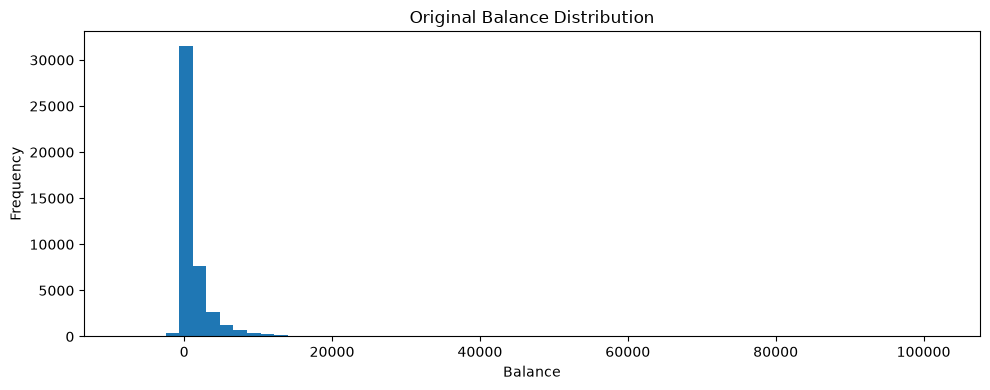

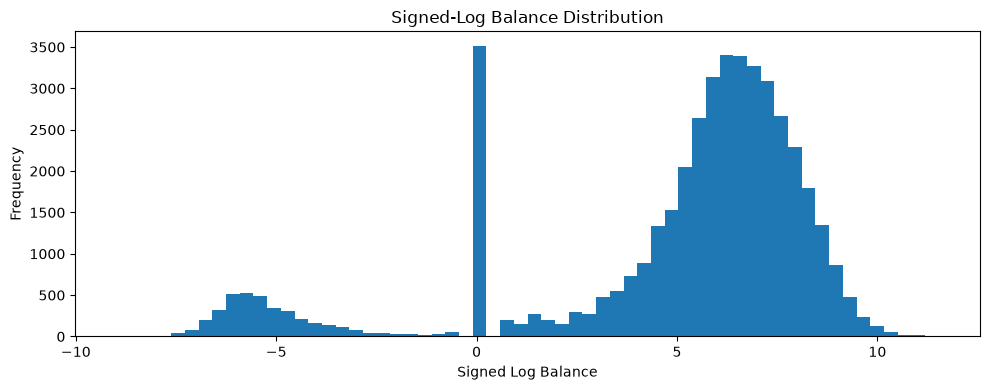

In [53]:
# Visual comparison: original balance vs transformed balance

plt.figure(figsize=(10, 4))
plt.hist(
    bank_processed["balance"],
    bins=60
)
plt.title("Original Balance Distribution")
plt.xlabel("Balance")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(
    bank_processed["balance_signed_log"],
    bins=60
)
plt.title("Signed-Log Balance Distribution")
plt.xlabel("Signed Log Balance")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Validate the Processed Dataset

Validation checks that Feature Engineering did not accidentally remove rows and that the newly created columns exist as expected.

In [54]:
# Validate row preservation

print("Original rows:", len(bank))
print("Processed rows:", len(bank_processed))
print("Original columns:", bank.shape[1])
print("Processed columns:", bank_processed.shape[1])

assert len(bank_processed) == len(bank), "Feature Engineering unexpectedly changed the row count."

new_columns = [
    column
    for column in bank_processed.columns
    if column not in bank.columns
]

print("\nNew engineered features:")
for column in new_columns:
    print("-", column)

Original rows: 45211
Processed rows: 45211
Original columns: 17
Processed columns: 28

New engineered features:
- age_group
- was_previously_contacted
- total_contacts
- age_iqr_outlier
- balance_iqr_outlier
- duration_iqr_outlier
- campaign_iqr_outlier
- outlier_flag_count
- balance_signed_log
- duration_log
- campaign_log


In [55]:
# Summary of outlier flags in the processed dataset

outlier_flag_summary = pd.DataFrame({
    "feature": OUTLIER_FEATURES,
    "iqr_flagged_rows": [
        bank_processed[f"{feature}_iqr_outlier"].sum()
        for feature in OUTLIER_FEATURES
    ]
})

display(outlier_flag_summary)

,feature,iqr_flagged_rows
0,age,487
1,balance,4729
2,duration,3235
3,campaign,3064


## Upload the Processed Data to Neon

The processed data is stored in a new table instead of replacing the raw table.

This keeps the project reproducible:

- `bank_marketing_raw` = original source data
- `bank_marketing_processed` = engineered features and outlier flags

In [56]:
PROCESSED_TABLE = "bank_marketing_processed"

db.upload_dataframe(
    bank_processed,
    table_name=PROCESSED_TABLE,
    if_exists="replace"
)

# Verify the processed table directly from Neon
verification = db.fetch_dataframe(
    f'SELECT COUNT(*) AS row_count FROM "{PROCESSED_TABLE}"'
)

display(verification)

✅ Successfully uploaded 45211 rows to 'bank_marketing_processed'.


,row_count
0,45211


## Summary and Conclusions

### Outlier Detection

Both Z-Score and IQR identified potential outliers, but they did not identify the same number of observations.

IQR flagged more values in the highly skewed features `balance`, `duration`, and `campaign`. This is expected because IQR uses quartiles and is less affected by very large observations.

Z-Score is still useful because it gives a standardized measure of distance from the mean, but it should be interpreted carefully when the distribution is strongly skewed.

### Outlier Treatment

The potential outliers were **not automatically deleted**.

The extreme values can represent real customers and real campaign activity. Instead, the project:

- preserves the original rows;
- adds IQR outlier flags;
- creates transformed numeric features; and
- keeps the original numeric columns for reference.

### Feature Engineering

New features were created to make the data easier to use in later machine-learning work:

- `age_group`
- `was_previously_contacted`
- `total_contacts`
- IQR outlier indicators
- `outlier_flag_count`
- `balance_signed_log`
- `duration_log`
- `campaign_log`
